# Experiment Result Parser

This notebook evaluates an explicit list of experiment/model paths instead of auto-selecting the latest runs. `EXPERIMENT_PATHS` is currently set to the latest completed SI scenario runs for every model and modality from the partitioned training process. Add run directories, `summary.json` files, or model weight files to `EXPERIMENT_PATHS`; nested lists are allowed when you want to keep related experiments grouped in the input. The notebook will flatten that list, load each run summary, and then:

- compares model parameter counts first,
- plots learning history for accuracy and F1,
- builds testing tables from the selected stored metrics.


In [1]:
from __future__ import annotations

import json
from collections.abc import Iterable
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

PROJECT_ROOT = Path.cwd()
EXPERIMENT_ROOT = PROJECT_ROOT / "artifacts" / "experiments"

if not EXPERIMENT_ROOT.exists():
    raise FileNotFoundError(
        "Expected to run this notebook from the repository root so that 'artifacts/experiments' is available."
    )

# Put the exact experiments you want to evaluate here. Each entry may be:
# - a run directory: artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z
# - a summary file: artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z/summary.json
# - a model weights file: artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z/best.weights.h5
# Nested lists/tuples are flattened, so you can group related experiments while still evaluating them together.
EXPERIMENT_PATHS = [
    # SI / hand
    [
        "artifacts/experiments/si/cnn1d/hand/20260614T174802Z",
        "artifacts/experiments/si/gcn/hand/20260619T103334Z",
        "artifacts/experiments/si/lstm/hand/20260615T093525Z",
        "artifacts/experiments/si/transformer/hand/20260618T112822Z",
    ],
    # SI / hand + body
    [
        "artifacts/experiments/si/cnn1d/hand_body/20260614T201315Z",
        "artifacts/experiments/si/gcn/hand_body/20260619T132838Z",
        "artifacts/experiments/si/lstm/hand_body/20260615T233635Z",
        "artifacts/experiments/si/transformer/hand_body/20260618T155746Z",
    ],
    # SI / hand + face
    [
        "artifacts/experiments/si/cnn1d/hand_face/20260614T225317Z",
        "artifacts/experiments/si/gcn/hand_face/20260619T163429Z",
        "artifacts/experiments/si/lstm/hand_face/20260616T142144Z",
        "artifacts/experiments/si/transformer/hand_face/20260618T200259Z",
    ],
    # SI / body + hand + face
    [
        "artifacts/experiments/si/cnn1d/body_hand_face/20260615T034844Z",
        "artifacts/experiments/si/gcn/body_hand_face/20260619T221441Z",
        "artifacts/experiments/si/lstm/body_hand_face/20260620T045322Z",
        "artifacts/experiments/si/transformer/body_hand_face/20260619T025735Z",
    ],
]


def load_json(path: Path) -> dict:
    return json.loads(path.read_text())


def flatten_experiment_paths(paths: Iterable) -> list[str | Path]:
    flattened = []
    for item in paths:
        if isinstance(item, (str, Path)):
            flattened.append(item)
        elif isinstance(item, Iterable):
            flattened.extend(flatten_experiment_paths(item))
        else:
            raise TypeError(f"Unsupported experiment path entry: {item!r}")
    return flattened


def resolve_project_path(path_like: str | Path) -> Path:
    path = Path(path_like).expanduser()
    if not path.is_absolute():
        path = PROJECT_ROOT / path
    return path.resolve()


def resolve_run_dir(path_like: str | Path) -> Path:
    path = resolve_project_path(path_like)
    if path.is_dir():
        run_dir = path
    elif path.name == "summary.json":
        run_dir = path.parent
    elif path.suffix in {".h5", ".keras"} or path.name.endswith(".weights.h5"):
        run_dir = path.parent
    else:
        raise ValueError(
            f"Expected a run directory, summary.json, or model weights file; got: {path_like}"
        )

    summary_path = run_dir / "summary.json"
    if not summary_path.exists():
        raise FileNotFoundError(f"Could not find summary.json for selected experiment: {run_dir}")
    return run_dir


def infer_run_parts(run_dir: Path) -> tuple[str, str, str, str]:
    try:
        relative = run_dir.relative_to(EXPERIMENT_ROOT)
        scenario, model, modality, run_id = relative.parts[:4]
    except ValueError:
        scenario, model, modality, run_id = run_dir.parts[-4:]
    return scenario, model, modality, run_id


def display_path(path: Path) -> str:
    if path.is_relative_to(PROJECT_ROOT):
        return str(path.relative_to(PROJECT_ROOT))
    return str(path)


def run_to_row(run_dir: Path) -> dict:
    scenario, model, modality, run_id = infer_run_parts(run_dir)
    summary_path = run_dir / "summary.json"
    history_path = run_dir / "history.json"
    metrics_path = run_dir / "metrics.json"
    summary = load_json(summary_path)
    config = load_json(run_dir / "config.json")
    metrics = summary.get("metrics", {})
    return {
        "scenario": scenario,
        "model": model,
        "modality": modality,
        "combination": f"{model} | {modality}",
        "run_id": run_id,
        "run_dir": display_path(run_dir),
        "summary_path": display_path(summary_path),
        "history_path": display_path(history_path),
        "metrics_path": display_path(metrics_path),
        "config_path": display_path(run_dir / "config.json"),
        "parameter_count": summary.get("parameter_count"),
        "input_shape": tuple(summary.get("input_shape", [])),
        "frame_sample_count": config.get("frame_sample_count"),
        "seed": config.get("seed"),
        "train_size": summary.get("train_size"),
        "test_size": summary.get("test_size"),
        "num_classes": summary.get("num_classes"),
        "test_accuracy": metrics.get("accuracy"),
        "test_f1_score": metrics.get("f1_score"),
        "test_loss": metrics.get("loss"),
    }


def format_shape(shape) -> str:
    if not shape:
        return "?"
    return "x".join(str(part) for part in shape)


def add_display_labels(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    duplicate_model = frame.duplicated("model", keep=False)
    labels = []
    for row_index, row in frame.iterrows():
        if duplicate_model.loc[row_index]:
            labels.append(
                f"{row['model']} | {row['modality']}\n"
                f"{row['scenario'].upper()} {format_shape(row['input_shape'])} seed={row['seed']}"
            )
        else:
            labels.append(f"{row['model']} | {row['modality']}")

    frame["display_label"] = labels
    duplicate_label = frame.duplicated("display_label", keep=False)
    frame.loc[duplicate_label, "display_label"] = (
        frame.loc[duplicate_label, "display_label"] + "\n" + frame.loc[duplicate_label, "run_id"]
    )

    palette = [
        f"#{int(r * 255):02x}{int(g * 255):02x}{int(b * 255):02x}"
        for r, g, b, _ in (plt.cm.tab20(index % 20) for index in range(len(frame)))
    ]
    frame["display_color"] = palette
    return frame


def collect_selected_runs(paths: Iterable) -> pd.DataFrame:
    run_dirs = []
    seen = set()
    for selected_path in flatten_experiment_paths(paths):
        run_dir = resolve_run_dir(selected_path)
        if run_dir not in seen:
            run_dirs.append(run_dir)
            seen.add(run_dir)

    if not run_dirs:
        raise ValueError("Add at least one experiment path to EXPERIMENT_PATHS.")

    frame = pd.DataFrame(run_to_row(run_dir) for run_dir in run_dirs)
    frame = frame.sort_values(["scenario", "model", "modality", "run_id"]).reset_index(drop=True)
    return add_display_labels(frame)


selected_runs = collect_selected_runs(EXPERIMENT_PATHS)
display(selected_runs)


,scenario,model,modality,combination,run_id,run_dir,summary_path,history_path,metrics_path,config_path,parameter_count,input_shape,frame_sample_count,seed,train_size,test_size,num_classes,test_accuracy,test_f1_score,test_loss,display_label,display_color
0,si,cnn1d,body_hand_face,cnn1d | body_hand_face,20260615T034844Z,artifacts/experiments/si/cnn1d/body_hand_face/...,artifacts/experiments/si/cnn1d/body_hand_face/...,artifacts/experiments/si/cnn1d/body_hand_face/...,artifacts/experiments/si/cnn1d/body_hand_face/...,artifacts/experiments/si/cnn1d/body_hand_face/...,1479979,"(30, 2765)",30,128,40366,32941,2731,0.092468,0.087135,5.913048,cnn1d | body_hand_face\nSI 30x2765 seed=128,#1f77b4
1,si,cnn1d,hand,cnn1d | hand,20260614T174802Z,artifacts/experiments/si/cnn1d/hand/20260614T1...,artifacts/experiments/si/cnn1d/hand/20260614T1...,artifacts/experiments/si/cnn1d/hand/20260614T1...,artifacts/experiments/si/cnn1d/hand/20260614T1...,artifacts/experiments/si/cnn1d/hand/20260614T1...,498859,"(30, 210)",30,128,40366,32941,2731,0.259342,0.254943,5.071100,cnn1d | hand\nSI 30x210 seed=128,#aec7e8
2,si,cnn1d,hand_body,cnn1d | hand_body,20260614T201315Z,artifacts/experiments/si/cnn1d/hand_body/20260...,artifacts/experiments/si/cnn1d/hand_body/20260...,artifacts/experiments/si/cnn1d/hand_body/20260...,artifacts/experiments/si/cnn1d/hand_body/20260...,artifacts/experiments/si/cnn1d/hand_body/20260...,562219,"(30, 375)",30,128,40366,32941,2731,0.301661,0.299007,4.928476,cnn1d | hand_body\nSI 30x375 seed=128,#ff7f0e
3,si,cnn1d,hand_face,cnn1d | hand_face,20260614T225317Z,artifacts/experiments/si/cnn1d/hand_face/20260...,artifacts/experiments/si/cnn1d/hand_face/20260...,artifacts/experiments/si/cnn1d/hand_face/20260...,artifacts/experiments/si/cnn1d/hand_face/20260...,artifacts/experiments/si/cnn1d/hand_face/20260...,1416619,"(30, 2600)",30,128,40366,32941,2731,0.081783,0.076523,6.128114,cnn1d | hand_face\nSI 30x2600 seed=128,#ffbb78
4,si,gcn,body_hand_face,gcn | body_hand_face,20260619T221441Z,artifacts/experiments/si/gcn/body_hand_face/20...,artifacts/experiments/si/gcn/body_hand_face/20...,artifacts/experiments/si/gcn/body_hand_face/20...,artifacts/experiments/si/gcn/body_hand_face/20...,artifacts/experiments/si/gcn/body_hand_face/20...,989517,"(30, 2765)",30,128,40366,32941,2731,0.301448,0.298862,3.998196,gcn | body_hand_face\nSI 30x2765 seed=128,#2ca02c
5,si,gcn,hand,gcn | hand,20260619T103334Z,artifacts/experiments/si/gcn/hand/20260619T103...,artifacts/experiments/si/gcn/hand/20260619T103...,artifacts/experiments/si/gcn/hand/20260619T103...,artifacts/experiments/si/gcn/hand/20260619T103...,artifacts/experiments/si/gcn/hand/20260619T103...,381427,"(30, 210)",30,128,40366,32941,2731,0.272639,0.265440,4.427376,gcn | hand\nSI 30x210 seed=128,#98df8a
6,si,gcn,hand_body,gcn | hand_body,20260619T132838Z,artifacts/experiments/si/gcn/hand_body/2026061...,artifacts/experiments/si/gcn/hand_body/2026061...,artifacts/experiments/si/gcn/hand_body/2026061...,artifacts/experiments/si/gcn/hand_body/2026061...,artifacts/experiments/si/gcn/hand_body/2026061...,389149,"(30, 375)",30,128,40366,32941,2731,0.300325,0.296853,4.141792,gcn | hand_body\nSI 30x375 seed=128,#d62728
7,si,gcn,hand_face,gcn | hand_face,20260619T163429Z,artifacts/experiments/si/gcn/hand_face/2026061...,artifacts/experiments/si/gcn/hand_face/2026061...,artifacts/experiments/si/gcn/hand_face/2026061...,artifacts/experiments/si/gcn/hand_face/2026061...,artifacts/experiments/si/gcn/hand_face/2026061...,918699,"(30, 2600)",30,128,40366,32941,2731,0.191524,0.185000,5.236109,gcn | hand_face\nSI 30x2600 seed=128,#ff9896
8,si,lstm,body_hand_face,lstm | body_hand_face,20260620T045322Z,artifacts/experiments/si/lstm/body_hand_face/2...,artifacts/experiments/si/lstm/body_hand_face/2...,artifacts/experiments/si/lstm/body_hand_face/2...,artifacts/experiments/si/lstm/body_hand_face/2...,artifacts/experiments/si/lstm/body_hand_face/2...,3496619,"(30, 2765)",30,128,40366,32941,2731,0.159922,0.150777,4.73277

,display_label,scenario,model,modality,run_id,input_shape
0,cnn1d | body_hand_face\nSI 30x2765 seed=128,si,cnn1d,body_hand_face,20260615T034844Z,"(30, 2765)"
1,cnn1d | hand\nSI 30x210 seed=128,si,cnn1d,hand,20260614T174802Z,"(30, 210)"
2,cnn1d | hand_body\nSI 30x375 seed=128,si,cnn1d,hand_body,20260614T201315Z,"(30, 375)"
3,cnn1d | hand_face\nSI 30x2600 seed=128,si,cnn1d,hand_face,20260614T225317Z,"(30, 2600)"
4,gcn | body_hand_face\nSI 30x2765 seed=128,si,gcn,body_hand_face,20260619T221441Z,"(30, 2765)"
5,gcn | hand\nSI 30x210 seed=128,si,gcn,hand,20260619T103334Z,"(30, 210)"
6,gcn | hand_body\nSI 30x375 seed=128,si,gcn,hand_body,20260619T132838Z,"(30, 375)"
7,gcn | hand_face\nSI 30x2600 seed=128,si,gcn,hand_face,20260619T163429Z,"(30, 2600)"
8,lstm | body_hand_face\nSI 30x2765 seed=128,si,lstm,body_hand_face,20260620T045322Z,"(30, 2765)"
9,lstm | hand\nSI 30x210 seed=128,si,lstm,hand,20260615T093525Z,"(30, 210)"


display_label,cnn1d | body_hand_face\nSI 30x2765 seed=128,cnn1d | hand\nSI 30x210 seed=128,cnn1d | hand_body\nSI 30x375 seed=128,cnn1d | hand_face\nSI 30x2600 seed=128,gcn | body_hand_face\nSI 30x2765 seed=128,gcn | hand\nSI 30x210 seed=128,gcn | hand_body\nSI 30x375 seed=128,gcn | hand_face\nSI 30x2600 seed=128,lstm | body_hand_face\nSI 30x2765 seed=128,lstm | hand\nSI 30x210 seed=128,lstm | hand_body\nSI 30x375 seed=128,lstm | hand_face\nSI 30x2600 seed=128,transformer | body_hand_face\nSI 30x2765 seed=128,transformer | hand\nSI 30x210 seed=128,transformer | hand_body\nSI 30x375 seed=128,transformer | hand_face\nSI 30x2600 seed=128
scenario,si,si,si,si,si,si,si,si,si,si,si,si,si,si,si,si
model,cnn1d,cnn1d,cnn1d,cnn1d,gcn,gcn,gcn,gcn,lstm,lstm,lstm,lstm,transformer,transformer,transformer,transformer
modality,body_hand_face,hand,hand_body,hand_face,body_hand_face,hand,hand_body,hand_face,body_hand_face,hand,hand_body,hand_face,body_hand_face,hand,hand_body,hand_face
run_id,20260615T034844Z,20260614T174802Z,20260614T201315Z,20260614T225317Z,20260619T221441Z,20260619T103334Z,20260619T132838Z,20260619T163429Z,20260620T045322Z,20260615T093525Z,20260615T233635Z,20260616T142144Z,20260619T025735Z,20260618T112822Z,20260618T155746Z,20260618T200259Z
input_shape,"(30, 2765)","(30, 210)","(30, 375)","(30, 2600)","(30, 2765)","(30, 210)","(30, 375)","(30, 2600)","(30, 2765)","(30, 210)","(30, 375)","(30, 2600)","(30, 2765)","(30, 210)","(30, 375)","(30, 2600)"


,display_label,model,modality,scenario,run_id,frame_sample_count,seed,parameter_count,input_shape,num_classes
0,lstm | body_hand_face\nSI 30x2765 seed=128,lstm,body_hand_face,si,20260620T045322Z,30,128,3496619,"(30, 2765)",2731
1,lstm | hand_face\nSI 30x2600 seed=128,lstm,hand_face,si,20260616T142144Z,30,128,3327659,"(30, 2600)",2731
2,cnn1d | body_hand_face\nSI 30x2765 seed=128,cnn1d,body_hand_face,si,20260615T034844Z,30,128,1479979,"(30, 2765)",2731
3,cnn1d | hand_face\nSI 30x2600 seed=128,cnn1d,hand_face,si,20260614T225317Z,30,128,1416619,"(30, 2600)",2731
4,transformer | body_hand_face\nSI 30x2765 seed=128,transformer,body_hand_face,si,20260619T025735Z,30,128,1366827,"(30, 2765)",2731
5,transformer | hand_face\nSI 30x2600 seed=128,transformer,hand_face,si,20260618T200259Z,30,128,1345707,"(30, 2600)",2731
6,transformer | hand_body\nSI 30x375 seed=128,transformer,hand_body,si,20260618T155746Z,30,128,1060907,"(30, 375)",2731
7,lstm | hand_body\nSI 30x375 seed=128,lstm,hand_body,si,20260615T233635Z,30,128,1049259,"(30, 375)",2731
8,transformer | hand\nSI 30x210 seed=128,transformer,hand,si,20260618T112822Z,30,128,1039787,"(30, 210)",2731
9,gcn | body_hand_face\nSI 30x2765 seed=128,gcn,body_hand_face,si,20260619T221441Z,30,128,989517,"(30, 2765)",2731


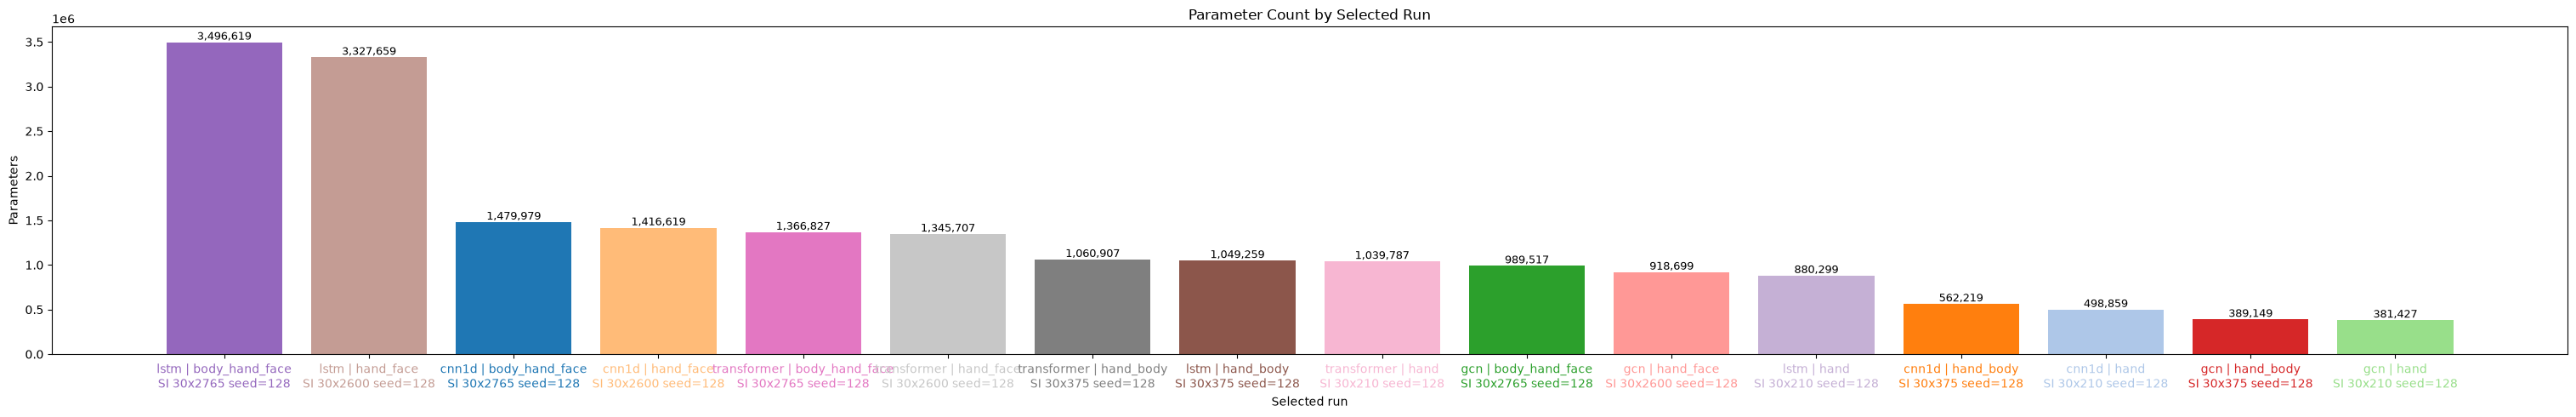

In [2]:
# Config and parameter comparison
def flatten_config(config: dict, prefix: str = "") -> dict:
    flattened = {}
    for key, value in config.items():
        full_key = f"{prefix}.{key}" if prefix else key
        if isinstance(value, dict):
            flattened.update(flatten_config(value, full_key))
        elif isinstance(value, list):
            flattened[full_key] = tuple(value)
        else:
            flattened[full_key] = value
    return flattened


config_rows = []
for run in selected_runs.itertuples(index=False):
    config_path = PROJECT_ROOT / run.config_path
    config = flatten_config(load_json(config_path))
    config_rows.append(
        {
            "display_label": run.display_label,
            "scenario": run.scenario,
            "model": run.model,
            "modality": run.modality,
            "run_id": run.run_id,
            **config,
        }
    )

config_table = pd.DataFrame(config_rows)
identity_columns = ["display_label", "scenario", "model", "modality", "run_id"]
config_columns = [column for column in config_table.columns if column not in identity_columns]
varying_config_columns = [
    column
    for column in config_columns
    if config_table[column].nunique(dropna=False) > 1
]

display(config_table[identity_columns + varying_config_columns])

config_compare = config_table.set_index(identity_columns).T
config_compare = config_compare.loc[varying_config_columns]
display(config_compare)

parameter_table = (
    selected_runs[[
        "display_label",
        "model",
        "modality",
        "scenario",
        "run_id",
        "frame_sample_count",
        "seed",
        "parameter_count",
        "input_shape",
        "num_classes",
    ]]
    .sort_values(["parameter_count", "model", "modality", "scenario", "run_id"], ascending=[False, True, True, True, True])
    .reset_index(drop=True)
)
display(parameter_table)

parameter_plot = selected_runs.sort_values(
    ["parameter_count", "model", "modality", "scenario", "run_id"],
    ascending=[False, True, True, True, True],
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(max(10, 1.9 * len(parameter_plot)), 5))
ax.bar(parameter_plot["display_label"], parameter_plot["parameter_count"], color=parameter_plot["display_color"])
ax.set_title("Parameter Count by Selected Run")
ax.set_ylabel("Parameters")
ax.set_xlabel("Selected run")
ax.tick_params(axis="x", rotation=0)
for tick, color in zip(ax.get_xticklabels(), parameter_plot["display_color"]):
    tick.set_color(color)
for index, value in enumerate(parameter_plot["parameter_count"]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


,scenario,model,modality,series,run_id,cycle,split,metric,value
0,si,cnn1d,body_hand_face,cnn1d | body_hand_face\nSI 30x2765 seed=128,20260615T034844Z,1,train,accuracy,0.000359
1,si,cnn1d,body_hand_face,cnn1d | body_hand_face\nSI 30x2765 seed=128,20260615T034844Z,2,train,accuracy,0.000421
2,si,cnn1d,body_hand_face,cnn1d | body_hand_face\nSI 30x2765 seed=128,20260615T034844Z,3,train,accuracy,0.000582
3,si,cnn1d,body_hand_face,cnn1d | body_hand_face\nSI 30x2765 seed=128,20260615T034844Z,4,train,accuracy,0.000917
4,si,cnn1d,body_hand_face,cnn1d | body_hand_face\nSI 30x2765 seed=128,20260615T034844Z,5,train,accuracy,0.000780


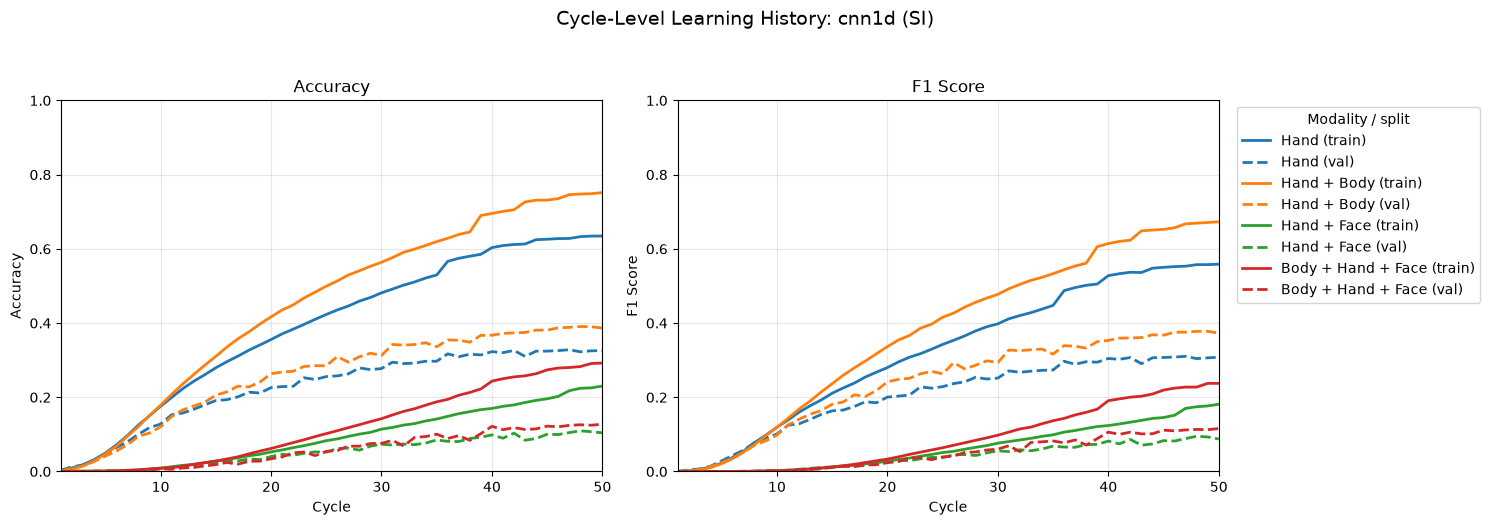

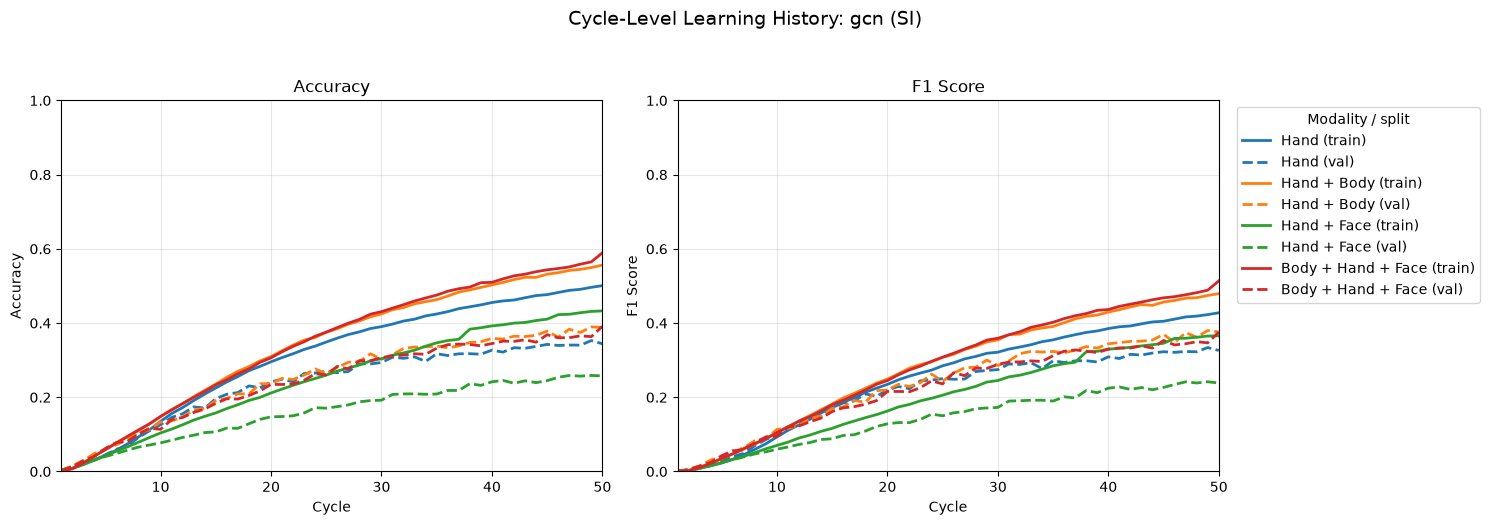

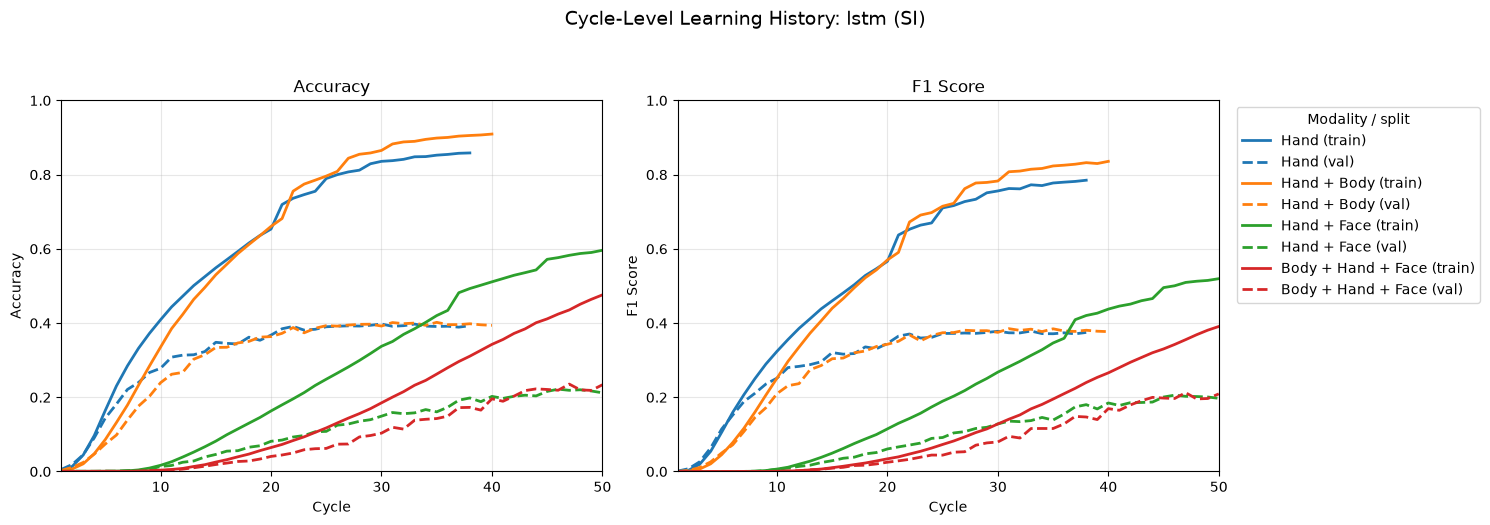

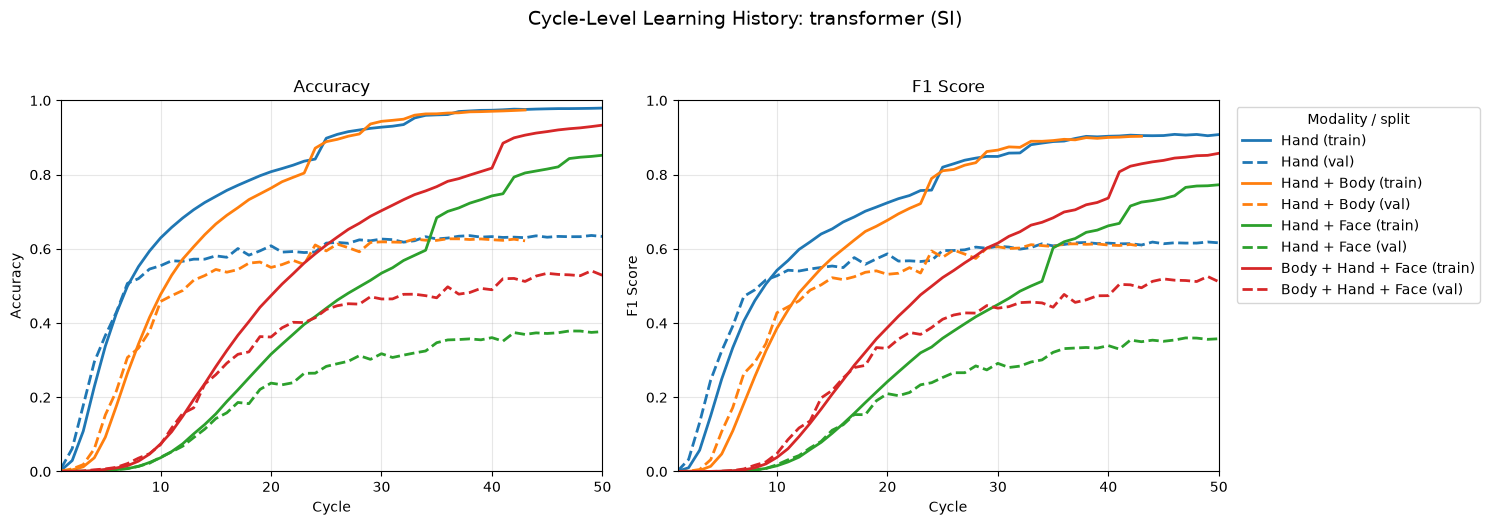

In [3]:
def build_cycle_history_frame(selected_frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    keys = {
        ("train", "accuracy"): "accuracy",
        ("val", "accuracy"): "val_accuracy",
        ("train", "f1_score"): "f1_score",
        ("val", "f1_score"): "val_f1_score",
    }

    for run in selected_frame.itertuples(index=False):
        history = load_json(PROJECT_ROOT / run.history_path)
        config = load_json(PROJECT_ROOT / run.config_path)
        epochs_per_partition = int(config.get("epochs", 1) or 1)
        train_partitions = int(config.get("train_partitions", 1) or 1)
        partition_epochs_per_cycle = max(1, epochs_per_partition * train_partitions)

        for (split, metric), history_key in keys.items():
            values = history.get(history_key, [])
            if split == "train":
                cycle_values = {}
                for step, value in enumerate(values, start=1):
                    cycle = (step - 1) // partition_epochs_per_cycle + 1
                    cycle_values.setdefault(cycle, []).append(value)
                iterable = (
                    (cycle, sum(cycle_items) / len(cycle_items))
                    for cycle, cycle_items in sorted(cycle_values.items())
                )
            else:
                # Validation is recorded once after each full partition cycle.
                iterable = enumerate(values, start=1)

            for cycle, value in iterable:
                rows.append(
                    {
                        "scenario": run.scenario,
                        "model": run.model,
                        "modality": run.modality,
                        "series": run.display_label,
                        "run_id": run.run_id,
                        "cycle": cycle,
                        "split": split,
                        "metric": metric,
                        "value": value,
                    }
                )
    return pd.DataFrame(rows)


history_df = build_cycle_history_frame(selected_runs)
display(history_df.head())

if history_df.empty:
    raise ValueError("No history rows were built from the selected experiments.")

model_order = [model for model in ["cnn1d", "gcn", "lstm", "transformer"] if model in set(history_df["model"])]
modality_order = [
    modality
    for modality in ["hand", "hand_body", "hand_face", "body_hand_face"]
    if modality in set(history_df["modality"])
]
modality_labels = {
    "hand": "Hand",
    "hand_body": "Hand + Body",
    "hand_face": "Hand + Face",
    "body_hand_face": "Body + Hand + Face",
}
metric_specs = [("accuracy", "Accuracy"), ("f1_score", "F1 Score")]
modality_colors = dict(zip(modality_order, plt.cm.tab10.colors[: len(modality_order)]))
split_styles = {"train": "-", "val": "--"}

for model in model_order:
    model_history = history_df[history_df["model"] == model].copy()
    if model_history.empty:
        continue

    fig, axes = plt.subplots(1, len(metric_specs), figsize=(15, 5), sharex=True, squeeze=False)
    legend_handles = {}

    for ax, (metric_name, title) in zip(axes[0], metric_specs):
        metric_history = model_history[model_history["metric"] == metric_name]

        for modality in modality_order:
            modality_history = metric_history[metric_history["modality"] == modality]
            if modality_history.empty:
                continue

            for split, linestyle in split_styles.items():
                line_history = modality_history[modality_history["split"] == split]
                if line_history.empty:
                    continue
                label = f"{modality_labels.get(modality, modality)} ({split})"
                line, = ax.plot(
                    line_history["cycle"],
                    line_history["value"],
                    color=modality_colors[modality],
                    linestyle=linestyle,
                    linewidth=2,
                    label=label,
                )
                legend_handles.setdefault(label, line)

        ax.set_title(title)
        ax.set_xlabel("Cycle")
        ax.set_ylabel(title)
        ax.set_xlim(1, max(history_df["cycle"]))
        ax.set_ylim(0, 1.0)
        ax.grid(alpha=0.3)

    axes[0, -1].legend(
        legend_handles.values(),
        legend_handles.keys(),
        title="Modality / split",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    scenario_names = ", ".join(sorted(model_history["scenario"].unique()))
    fig.suptitle(f"Cycle-Level Learning History: {model} ({scenario_names.upper()})", y=1.04, fontsize=14)
    fig.tight_layout()
    plt.show()


In [4]:
# Testing comparison tables for the selected SI runs
test_results_long = (
    selected_runs[[
        "display_label",
        "scenario",
        "model",
        "modality",
        "run_id",
        "frame_sample_count",
        "seed",
        "test_accuracy",
        "test_f1_score",
        "test_loss",
        "test_size",
    ]]
    .sort_values(["scenario", "model", "modality"])
    .reset_index(drop=True)
)
display(test_results_long)

test_results_compare = (
    selected_runs.pivot_table(
        index=["display_label", "model", "modality", "run_id"],
        columns="scenario",
        values=["test_accuracy", "test_f1_score", "test_loss"],
        aggfunc="first",
    )
    .swaplevel(0, 1, axis=1)
    .sort_index(axis=1, level=[0, 1])
)
display(test_results_compare)

best_by_scenario = (
    selected_runs.sort_values(["scenario", "test_accuracy", "test_f1_score"], ascending=[True, False, False])
    .groupby("scenario", as_index=False)
    .head(1)
    [["display_label", "scenario", "model", "modality", "run_id", "frame_sample_count", "seed", "test_accuracy", "test_f1_score", "test_loss"]]
    .reset_index(drop=True)
)
display(best_by_scenario)

selected_run_paths = selected_runs[["display_label", "scenario", "model", "modality", "run_id", "frame_sample_count", "seed", "input_shape", "run_dir"]].copy()
display(selected_run_paths)


,display_label,scenario,model,modality,run_id,frame_sample_count,seed,test_accuracy,test_f1_score,test_loss,test_size
0,cnn1d | body_hand_face\nSI 30x2765 seed=128,si,cnn1d,body_hand_face,20260615T034844Z,30,128,0.092468,0.087135,5.913048,32941
1,cnn1d | hand\nSI 30x210 seed=128,si,cnn1d,hand,20260614T174802Z,30,128,0.259342,0.254943,5.071100,32941
2,cnn1d | hand_body\nSI 30x375 seed=128,si,cnn1d,hand_body,20260614T201315Z,30,128,0.301661,0.299007,4.928476,32941
3,cnn1d | hand_face\nSI 30x2600 seed=128,si,cnn1d,hand_face,20260614T225317Z,30,128,0.081783,0.076523,6.128114,32941
4,gcn | body_hand_face\nSI 30x2765 seed=128,si,gcn,body_hand_face,20260619T221441Z,30,128,0.301448,0.298862,3.998196,32941
5,gcn | hand\nSI 30x210 seed=128,si,gcn,hand,20260619T103334Z,30,128,0.272639,0.265440,4.427376,32941
6,gcn | hand_body\nSI 30x375 seed=128,si,gcn,hand_body,20260619T132838Z,30,128,0.300325,0.296853,4.141792,32941
7,gcn | hand_face\nSI 30x2600 seed=128,si,gcn,hand_face,20260619T163429Z,30,128,0.191524,0.185000,5.236109,32941
8,lstm | body_hand_face\nSI 30x2765 seed=128,si,lstm,body_hand_face,20260620T045322Z,30,128,0.159922,0.150777,4.732775,32941
9,lstm | hand\nSI 30x210 seed=128,si,lstm,hand,20260615T093525Z,30,128,0.312984,0.309110,4.429760,32941


scenario                                                                                                 si  \
                                                                                              test_accuracy   
display_label                                     model       modality       run_id                           
cnn1d | body_hand_face\nSI 30x2765 seed=128       cnn1d       body_hand_face 20260615T034844Z      0.092468   
cnn1d | hand\nSI 30x210 seed=128                  cnn1d       hand           20260614T174802Z      0.259342   
cnn1d | hand_body\nSI 30x375 seed=128             cnn1d       hand_body      20260614T201315Z      0.301661   
cnn1d | hand_face\nSI 30x2600 seed=128            cnn1d       hand_face      20260614T225317Z      0.081783   
gcn | body_hand_face\nSI 30x2765 seed=128         gcn         body_hand_face 20260619T221441Z      0.301448   
gcn | hand\nSI 30x210 seed=128                    gcn         hand           20260619T103334Z      0.272639   
gcn | hand_body\nSI 30x375 seed=128               gcn         hand_body      20260619T132838Z      0.300325   
gcn | hand_face\nSI 30x2600 seed=128              gcn         hand_face      20260619T163429Z      0.191524   
lstm | body_hand_face\nSI 30x2765 seed=128        lstm        body_hand_face 20260620T045322Z      0.159922   
lstm | hand\nSI 30x210 seed=128                   lstm        hand           20260615T093525Z      0.312984   
lstm | hand_body\nSI 30x375 seed=128              lstm        hand_body      20260615T233635Z      0.306032   
lstm | hand_face\nSI 30x2600 seed=128             lstm        hand_face      20260616T142144Z      0.152303   
transformer | body_hand_face\nSI 30x2765 seed=128 transformer body_hand_face 20260619T025735Z      0.393006   
transformer | hand\nSI 30x210 seed=128            transformer hand           20260618T112822Z      0.514921   
transformer | hand_body\nSI 30x375 seed=128       transformer hand_body      20260618T155746Z      0.497860   
transformer | hand_face\nSI 30x2600 seed=128      transformer hand_face      20260618T200259Z      0.289973   

scenario                                                                                                     \
                                                                                              test_f1_score   
display_label                                     model       modality       run_id                           
cnn1d | body_hand_face\nSI 30x2765 seed=128       cnn1d       body_hand_face 20260615T034844Z      0.087135   
cnn1d | hand\nSI 30x210 seed=128                  cnn1d       hand           20260614T174802Z      0.254943   
cnn1d | hand_body\nSI 30x375 seed=128             cnn1d       hand_body      20260614T201315Z      0.299007   
cnn1d | hand_face\nSI 30x2600 seed=128            cnn1d       hand_face      20260614T225317Z      0.076523   
gcn | body_hand_face\nSI 30x2765 seed=128         gcn         body_hand_face 20260619T221441Z      0.298862   
gcn | hand\nSI 30x210 seed=128                    gcn         hand           20260619T103334Z      0.265440   
gcn | hand_body\nSI 30x375 seed=128               gcn         hand_body      20260619T132838Z      0.296853   
gcn | hand_face\nSI 30x2600 seed=128              gcn         hand_face      20260619T163429Z      0.185000   
lstm | body_hand_face\nSI 30x2765 seed=128        lstm        body_hand_face 20260620T045322Z      0.150777   
lstm | hand\nSI 30x210 seed=128                   lstm        hand           20260615T093525Z      0.309110   
lstm | hand_body\nSI 30x375 seed=128              lstm        hand_body      20260615T233635Z      0.303887   
lstm | hand_face\nSI 30x2600 seed=128             lstm        hand_face      20260616T142144Z      0.149348   
transformer | body_hand_face\nSI 30x2765 seed=128 transformer body_hand_face 20260619T025735Z      0.389743   
transformer | hand\nSI 30x210 seed=128            transformer hand           20260618T112822Z      0.512650   
tra

,display_label,scenario,model,modality,run_id,frame_sample_count,seed,test_accuracy,test_f1_score,test_loss
0,transformer | hand\nSI 30x210 seed=128,si,transformer,hand,20260618T112822Z,30,128,0.514921,0.512650,2.603510


,display_label,scenario,model,modality,run_id,frame_sample_count,seed,input_shape,run_dir
0,cnn1d | body_hand_face\nSI 30x2765 seed=128,si,cnn1d,body_hand_face,20260615T034844Z,30,128,"(30, 2765)",artifacts/experiments/si/cnn1d/body_hand_face/...
1,cnn1d | hand\nSI 30x210 seed=128,si,cnn1d,hand,20260614T174802Z,30,128,"(30, 210)",artifacts/experiments/si/cnn1d/hand/20260614T1...
2,cnn1d | hand_body\nSI 30x375 seed=128,si,cnn1d,hand_body,20260614T201315Z,30,128,"(30, 375)",artifacts/experiments/si/cnn1d/hand_body/20260...
3,cnn1d | hand_face\nSI 30x2600 seed=128,si,cnn1d,hand_face,20260614T225317Z,30,128,"(30, 2600)",artifacts/experiments/si/cnn1d/hand_face/20260...
4,gcn | body_hand_face\nSI 30x2765 seed=128,si,gcn,body_hand_face,20260619T221441Z,30,128,"(30, 2765)",artifacts/experiments/si/gcn/body_hand_face/20...
5,gcn | hand\nSI 30x210 seed=128,si,gcn,hand,20260619T103334Z,30,128,"(30, 210)",artifacts/experiments/si/gcn/hand/20260619T103...
6,gcn | hand_body\nSI 30x375 seed=128,si,gcn,hand_body,20260619T132838Z,30,128,"(30, 375)",artifacts/experiments/si/gcn/hand_body/2026061...
7,gcn | hand_face\nSI 30x2600 seed=128,si,gcn,hand_face,20260619T163429Z,30,128,"(30, 2600)",artifacts/experiments/si/gcn/hand_face/2026061...
8,lstm | body_hand_face\nSI 30x2765 seed=128,si,lstm,body_hand_face,20260620T045322Z,30,128,"(30, 2765)",artifacts/experiments/si/lstm/body_hand_face/2...
9,lstm | hand\nSI 30x210 seed=128,si,lstm,hand,20260615T093525Z,30,128,"(30, 210)",artifacts/experiments/si/lstm/hand/20260615T09...


## Model-Clustered Modality Comparison

This section groups the selected SI runs by model, then compares test performance across modalities inside each model cluster.


,model,modality,run_id,input_shape,parameter_count,test_accuracy,test_f1_score,test_loss,test_size
0,cnn1d,hand,20260614T174802Z,"(30, 210)",498859,0.259342,0.254943,5.071100,32941
1,cnn1d,hand_body,20260614T201315Z,"(30, 375)",562219,0.301661,0.299007,4.928476,32941
2,cnn1d,hand_face,20260614T225317Z,"(30, 2600)",1416619,0.081783,0.076523,6.128114,32941
3,cnn1d,body_hand_face,20260615T034844Z,"(30, 2765)",1479979,0.092468,0.087135,5.913048,32941
4,gcn,hand,20260619T103334Z,"(30, 210)",381427,0.272639,0.265440,4.427376,32941
5,gcn,hand_body,20260619T132838Z,"(30, 375)",389149,0.300325,0.296853,4.141792,32941
6,gcn,hand_face,20260619T163429Z,"(30, 2600)",918699,0.191524,0.185000,5.236109,32941
7,gcn,body_hand_face,20260619T221441Z,"(30, 2765)",989517,0.301448,0.298862,3.998196,32941
8,lstm,hand,20260615T093525Z,"(30, 210)",880299,0.312984,0.309110,4.429760,32941
9,lstm,hand_body,20260615T233635Z,"(30, 375)",1049259,0.306032,0.303887,4.475085,32941


Test Accuracy


modality,Hand,Hand + Body,Hand + Face,Body + Hand + Face
model,,,,
cnn1d,0.259342,0.301661,0.081783,0.092468
gcn,0.272639,0.300325,0.191524,0.301448
lstm,0.312984,0.306032,0.152303,0.159922
transformer,0.514921,0.497860,0.289973,0.393006


Test F1 Score


modality,Hand,Hand + Body,Hand + Face,Body + Hand + Face
model,,,,
cnn1d,0.254943,0.299007,0.076523,0.087135
gcn,0.265440,0.296853,0.185000,0.298862
lstm,0.309110,0.303887,0.149348,0.150777
transformer,0.512650,0.494703,0.285208,0.389743


Test Loss


modality,Hand,Hand + Body,Hand + Face,Body + Hand + Face
model,,,,
cnn1d,5.071100,4.928476,6.128114,5.913048
gcn,4.427376,4.141792,5.236109,3.998196
lstm,4.429760,4.475085,5.916689,4.732775
transformer,2.603510,2.520259,4.057111,3.425745


Best modality per model by test accuracy


,model,modality,run_id,test_accuracy,test_f1_score,test_loss
0,cnn1d,hand_body,20260614T201315Z,0.301661,0.299007,4.928476
1,gcn,body_hand_face,20260619T221441Z,0.301448,0.298862,3.998196
2,lstm,hand,20260615T093525Z,0.312984,0.309110,4.429760
3,transformer,hand,20260618T112822Z,0.514921,0.512650,2.603510


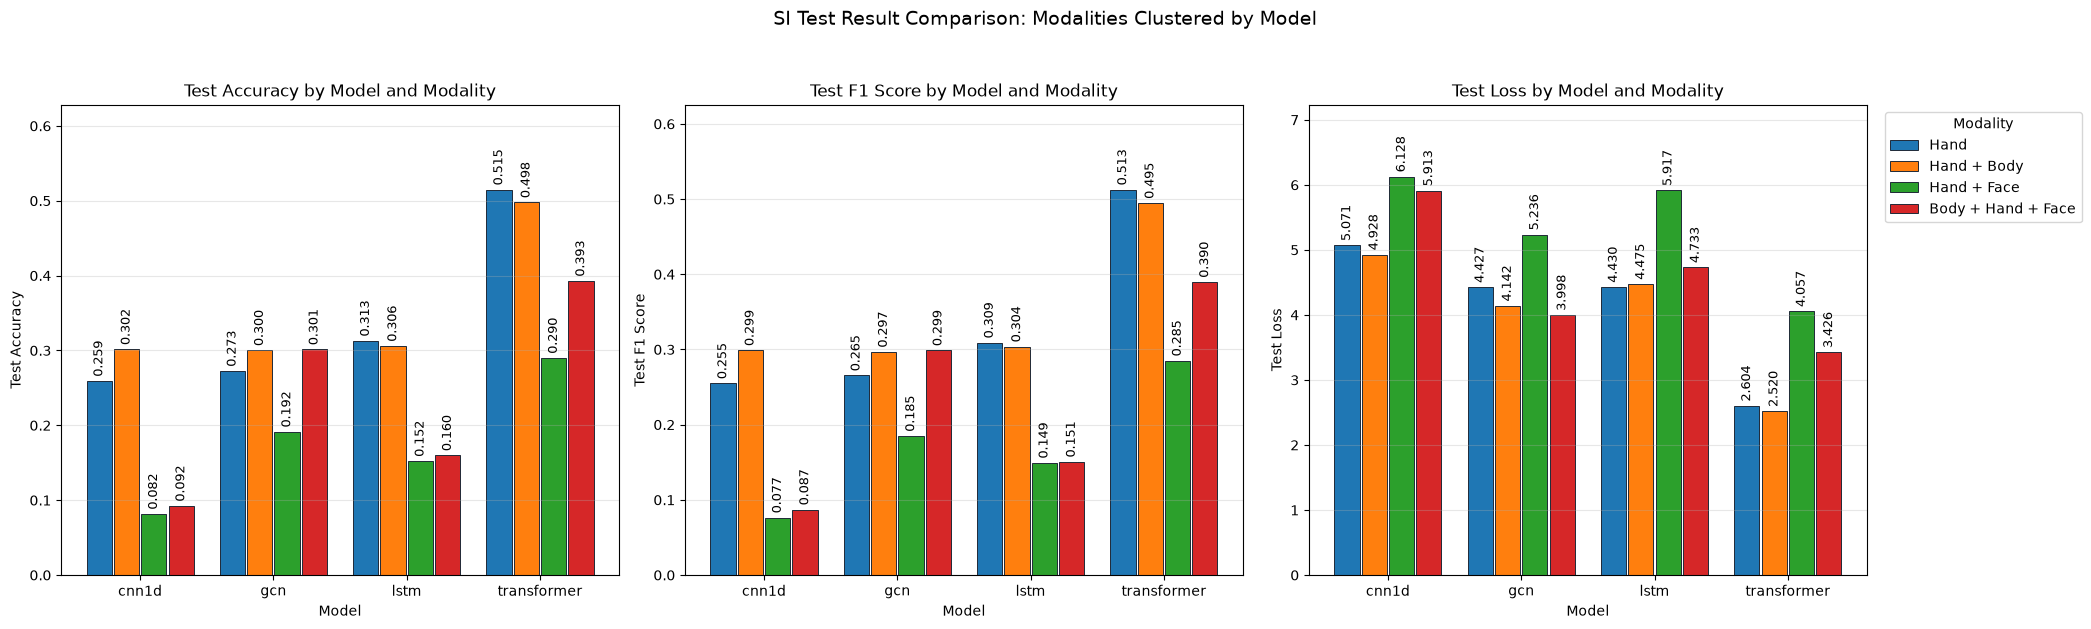

In [5]:
# Compare modalities inside each model cluster
model_order = [model for model in ["cnn1d", "gcn", "lstm", "transformer"] if model in set(selected_runs["model"])]
modality_order = [
    modality
    for modality in ["hand", "hand_body", "hand_face", "body_hand_face"]
    if modality in set(selected_runs["modality"])
]
modality_labels = {
    "hand": "Hand",
    "hand_body": "Hand + Body",
    "hand_face": "Hand + Face",
    "body_hand_face": "Body + Hand + Face",
}
metric_specs = [
    ("test_accuracy", "Test Accuracy", "higher"),
    ("test_f1_score", "Test F1 Score", "higher"),
    ("test_loss", "Test Loss", "lower"),
]

model_modality_results = selected_runs.copy()
model_modality_results["model"] = pd.Categorical(model_modality_results["model"], categories=model_order, ordered=True)
model_modality_results["modality"] = pd.Categorical(model_modality_results["modality"], categories=modality_order, ordered=True)
model_modality_results = model_modality_results.sort_values(["model", "modality"]).reset_index(drop=True)

display_columns = [
    "model",
    "modality",
    "run_id",
    "input_shape",
    "parameter_count",
    "test_accuracy",
    "test_f1_score",
    "test_loss",
    "test_size",
]
display(model_modality_results[display_columns])

metric_pivots = {}
for metric_name, metric_label, _ in metric_specs:
    pivot = (
        model_modality_results.pivot_table(
            index="model",
            columns="modality",
            values=metric_name,
            aggfunc="first",
            observed=False,
        )
        .reindex(index=model_order, columns=modality_order)
        .rename(columns=modality_labels)
    )
    metric_pivots[metric_name] = pivot
    print(metric_label)
    display(pivot)

best_accuracy_by_model = (
    model_modality_results.sort_values(["model", "test_accuracy", "test_f1_score"], ascending=[True, False, False])
    .groupby("model", observed=True)
    .head(1)
    [["model", "modality", "run_id", "test_accuracy", "test_f1_score", "test_loss"]]
    .reset_index(drop=True)
)
print("Best modality per model by test accuracy")
display(best_accuracy_by_model)

fig, axes = plt.subplots(1, len(metric_specs), figsize=(7 * len(metric_specs), 6), squeeze=False)
x_positions = list(range(len(model_order)))
bar_group_width = 0.82
bar_width = bar_group_width / max(1, len(modality_order))
modality_colors = dict(zip(modality_order, plt.cm.tab10.colors[: len(modality_order)]))

for ax, (metric_name, metric_label, direction) in zip(axes[0], metric_specs):
    raw_pivot = (
        model_modality_results.pivot_table(
            index="model",
            columns="modality",
            values=metric_name,
            aggfunc="first",
            observed=False,
        )
        .reindex(index=model_order, columns=modality_order)
    )
    metric_values = []
    for modality_index, modality in enumerate(modality_order):
        offsets = [position - bar_group_width / 2 + bar_width / 2 + modality_index * bar_width for position in x_positions]
        values = [raw_pivot.loc[model, modality] for model in model_order]
        metric_values.extend(value for value in values if pd.notna(value))
        bars = ax.bar(
            offsets,
            values,
            width=bar_width * 0.92,
            label=modality_labels.get(modality, modality),
            color=modality_colors[modality],
            edgecolor="#1f2937",
            linewidth=0.7,
        )
        labels = [f"{value:.3f}" if pd.notna(value) else "" for value in values]
        ax.bar_label(bars, labels=labels, padding=3, fontsize=9, rotation=90)

    ax.set_title(f"{metric_label} by Model and Modality")
    ax.set_xlabel("Model")
    ax.set_ylabel(metric_label)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(model_order)
    ax.grid(axis="y", alpha=0.3)
    if metric_values and direction == "higher":
        ax.set_ylim(0, min(1.0, max(metric_values) * 1.22))
    elif metric_values:
        ax.set_ylim(0, max(metric_values) * 1.18)

axes[0, -1].legend(title="Modality", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("SI Test Result Comparison: Modalities Clustered by Model", y=1.04, fontsize=14)
fig.tight_layout()
plt.show()
